# Lab 02 — 01. CIFAR-10: EDA và kiến trúc

Khảo sát ảnh RGB gốc và điều kiện đầu vào trước khi đọc notebook modeling.

| Bước | Nội dung | Hàm/file thực thi | Khi train | Khi view |
|---|---|---|---|---|
| 1 | Chọn run và môi trường | config, registry | run_suite tạo run mới | Đọc run được chỉ định |
| 2 | Kiểm chứng split/lớp | prepare_indices | Lưu indices | Đọc NPZ, kiểm tra đối chiếu dataset |
| 3 | Ảnh và thống kê | export_eda | Tính trên train | Bảng RGB và ảnh train |
| 4 | Tiền xử lý | image_transform | Resize/normalize trong loader | Gọi transform trên ảnh thật |
| 5 | Kiến trúc và freeze | build_model, configure_trainable | Nạp pretrained và thay head | Khảo sát cấu trúc, counts và tham số |

EDA không fit scaler trên validation/test. Normalization mô hình dùng thống kê ImageNet của pretrained weights; thống kê CIFAR-10 dưới đây phục vụ mô tả dữ liệu.


## 1. Run và môi trường

In [1]:
from pathlib import Path
import os, sys, json, inspect
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image, Markdown
candidates = [Path(os.environ.get('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents]
ROOT = next(p for p in candidates if (p / 'src' / 'experiment.py').exists())
sys.path.insert(0, str(ROOT))
override = os.environ.get('LAB02_RUN')
RUN = Path(override) if override else Path(json.loads((ROOT / 'outputs' / 'selected_run.json').read_text(encoding='utf-8'))['run'])
if not RUN.is_absolute():
    RUN = ROOT / RUN
cfg = json.loads((RUN / 'config.json').read_text(encoding='utf-8'))
assert cfg.get('dataset') == 'CIFAR10', 'Hãy chọn run CIFAR-10'
assert json.loads((RUN / 'status.json').read_text())['status'] == 'completed'
print('Run:', RUN)
display(cfg)
display(json.loads((RUN / 'environment.json').read_text(encoding='utf-8')))


Run: D:\DL\lab2\outputs\runs\20261024T075133Z_cifar10_cpu_full64_71863a0e


{'dataset': 'CIFAR10',
 'seed': 42,
 'threads': 4,
 'train_limit': 0,
 'val_limit': 0,
 'test_limit': 0,
 'models': ['resnet18', 'densenet121'],
 'learning_rates': [0.001, 0.01],
 'batch_sizes': [32, 64],
 'head_epochs': 5,
 'finetune_epochs': 2,
 'finetune_backbone_lr': 1e-05,
 'finetune_head_lr': 0.0001,
 'weight_decay': 0.0001,
 'feature_batch_size': 64,
 'image_size': 64,
 'profile': 'cifar10_cpu_full64',
 'notes': 'All 45000/5000/10000 samples. CPU budget: 64x64 RGB, fixed transforms; 5 head + 2 fine-tune epochs.'}

{'python': '3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]',
 'torch': '2.14.1+cpu',
 'torchvision': '0.29.1+cpu',
 'device': 'cpu',
 'platform': 'Windows-10-10.0.19041-SP0',
 'cpu_count': 8}

## 2. Kiểm chứng dữ liệu và split

In [2]:
from torchvision.datasets import CIFAR10
from src.data import prepare_indices, image_transform, IndexedImages
raw = CIFAR10(str(ROOT / 'data'), train=True, download=False)
official_test = CIFAR10(str(ROOT / 'data'), train=False, download=False)
full = dict(np.load(RUN / 'split_indices.npz'))
selected = dict(np.load(RUN / 'selected_indices.npz'))
assert len(raw) == 50000 and len(official_test) == 10000
assert not np.intersect1d(full['train'], full['val']).size
np.testing.assert_array_equal(np.union1d(full['train'], full['val']), np.arange(50000))
assert [len(full[s]) for s in ['train', 'val', 'test']] == [45000, 5000, 10000]
display(pd.read_csv(RUN / 'eda' / 'class_counts.csv', index_col=0))
print('Original image shape:', raw.data.shape[1:], 'dtype:', raw.data.dtype)
print(inspect.getsource(prepare_indices))


,train,val,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


Original image shape: (32, 32, 3) dtype: uint8
def prepare_indices(data_dir, run_dir, cfg):
    pool = datasets.CIFAR10(str(data_dir), train=True, download=True)
    test = datasets.CIFAR10(str(data_dir), train=False, download=True)
    train_idx, val_idx = train_test_split(
        np.arange(len(pool)), test_size=5000, random_state=cfg["seed"],
        stratify=np.asarray(pool.targets))
    full = {"train": np.sort(train_idx), "val": np.sort(val_idx),
            "test": np.arange(len(test))}
    selected = {s: balanced_subset(v, pool.targets if s != "test" else test.targets,
                                  cfg[f"{s}_limit"], cfg["seed"])
                for s, v in full.items()}
    np.savez(Path(run_dir) / "split_indices.npz", **full)
    np.savez(Path(run_dir) / "selected_indices.npz", **selected)
    return selected



## 3. Ảnh train và thống kê RGB

,channel,mean_train,std_train
0,R,0.491137,0.246869
1,G,0.482111,0.243430
2,B,0.446449,0.261603


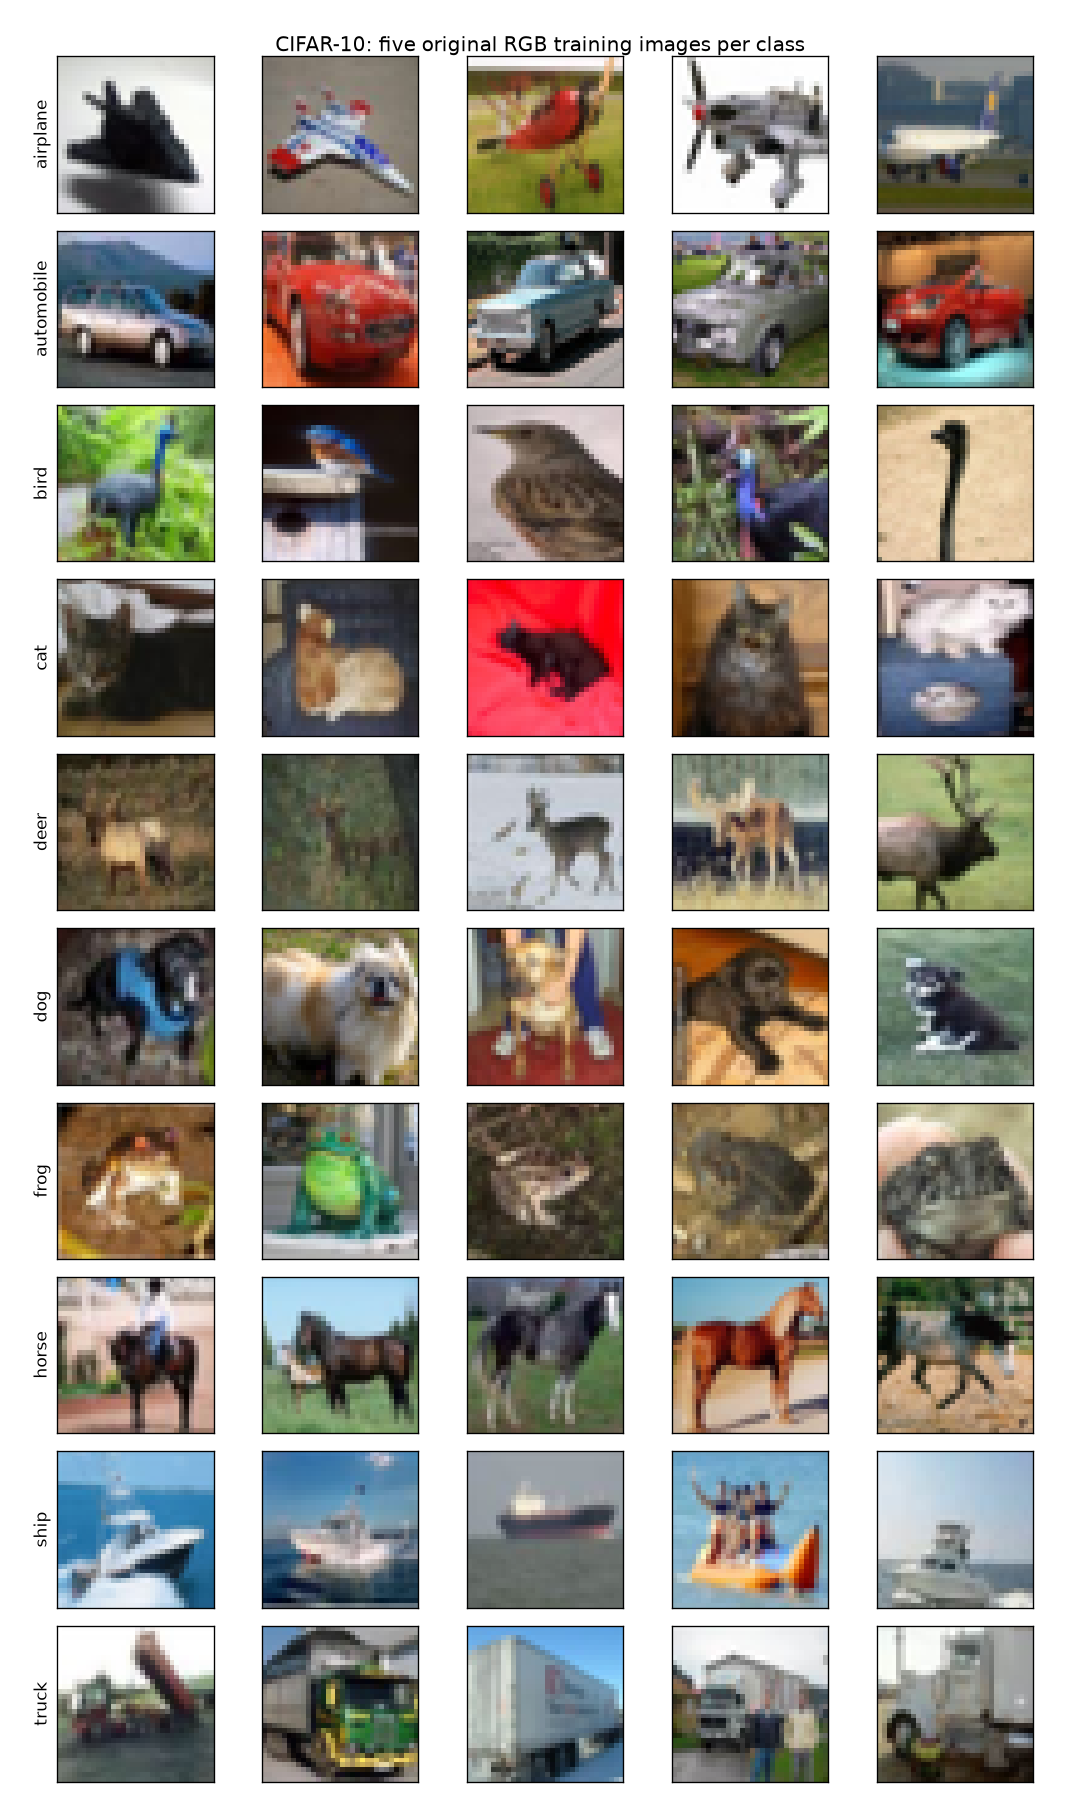

Descriptive train statistics only; pretrained ImageNet mean/std used for model input


In [3]:
summary = json.loads((RUN / 'eda' / 'summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame({'channel': ['R', 'G', 'B'], 'mean_train': summary['train_mean_rgb'], 'std_train': summary['train_std_rgb']}))
display(Image(filename=str(RUN / 'eda' / 'training_examples.png')))
print(summary['normalization_policy'])


## 4. Kiểm chứng preprocessing trên ảnh thật

Giữ màu RGB. CPU dùng resize trực tiếp 64×64; GPU dùng trọn transforms chính thức 224×224. Resize không khôi phục chi tiết mới. Không augmentation để cache feature nhất quán với fine-tuning. Có thể mở rộng augmentation sau như một thí nghiệm riêng.


def image_transform(name, image_size=224):
    """Preserve RGB. CPU profile changes spatial size, not ImageNet normalization."""
    weights_transform = SPECS[name][1].transforms()
    if image_size == 224:
        return weights_transform
    return transforms.Compose([
        transforms.Resize((image_size, image_size), antialias=True),
        transforms.ToTensor(),
        transforms.Normalize(weights_transform.mean, weights_transform.std),
    ])



resnet18 Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


densenet121 Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


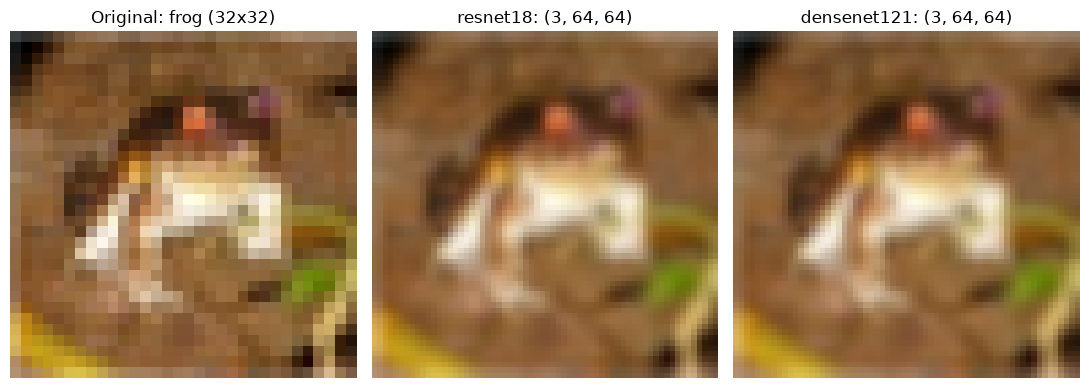

In [4]:
from src.models import SPECS
import matplotlib.pyplot as plt
print(inspect.getsource(image_transform))
index = int(selected['train'][0])
image, label = raw[index]
fig, axes = plt.subplots(1, 1 + len(cfg['models']), figsize=(11, 4))
axes[0].imshow(image)
axes[0].set_title(f'Original: {raw.classes[label]} (32x32)')
for ax, name in zip(axes[1:], cfg['models']):
    transform = image_transform(name, cfg['image_size'])
    processed = transform(image)
    dataset = IndexedImages(ROOT / 'data', 'train', [index], name, cfg['image_size'])
    loaded, actual, original_index = dataset[0]
    torch.testing.assert_close(processed, loaded)
    assert actual == label and original_index == index
    spec = SPECS[name][1].transforms()
    restored = processed * torch.tensor(spec.std)[:, None, None] + torch.tensor(spec.mean)[:, None, None]
    ax.imshow(restored.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f'{name}: {tuple(processed.shape)}')
    print(name, transform)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


## 5. Kiến trúc và tham số được học

Training nạp ImageNet `IMAGENET1K_V1`. Cell này dựng cùng kiến trúc với `pretrained=False` để khảo sát mà không tải weights; kiến trúc training thực tế đã được lưu trong artifact. Mỗi classifier xuất 10 logits, CrossEntropyLoss nhận logits trực tiếp.


In [5]:
from src.models import build_model, configure_trainable, parameter_counts
print(inspect.getsource(build_model))
print(inspect.getsource(configure_trainable))
rows = []
for name in cfg['models']:
    print((RUN / name / 'architecture.txt').read_text(encoding='utf-8'))
    model = build_model(name, pretrained=False)
    for stage in ['head', 'finetune']:
        configure_trainable(model, name, stage)
        rows.append({'model': name, 'stage': stage, **parameter_counts(model)})
        print(name, stage, 'trainable layers:')
        print([n for n, p in model.named_parameters() if p.requires_grad])
    display(pd.read_csv(RUN / name / 'parameters.csv'))
    del model
display(pd.DataFrame(rows))


def build_model(name, pretrained=True):
    builder, weights = SPECS[name]
    model = builder(weights=weights if pretrained else None)
    if name == "resnet18":
        model.fc = nn.Linear(model.fc.in_features, 10)
    else:
        model.classifier = nn.Linear(model.classifier.in_features, 10)
    return model

def configure_trainable(model, name, stage):
    for p in model.parameters():
        p.requires_grad = False
    for p in classifier(model, name).parameters():
        p.requires_grad = True
    if stage == "finetune":
        blocks = [model.layer4] if name == "resnet18" else [
            model.features.denseblock4, model.features.norm5]
        for block in blocks:
            for p in block.parameters():
                p.requires_grad = True

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (ma

resnet18 head trainable layers:
['fc.weight', 'fc.bias']
resnet18 finetune trainable layers:
['layer4.0.conv1.weight', 'layer4.0.bn1.weight', 'layer4.0.bn1.bias', 'layer4.0.conv2.weight', 'layer4.0.bn2.weight', 'layer4.0.bn2.bias', 'layer4.0.downsample.0.weight', 'layer4.0.downsample.1.weight', 'layer4.0.downsample.1.bias', 'layer4.1.conv1.weight', 'layer4.1.bn1.weight', 'layer4.1.bn1.bias', 'layer4.1.conv2.weight', 'layer4.1.bn2.weight', 'layer4.1.bn2.bias', 'fc.weight', 'fc.bias']


,name,shape,parameters,head_stage_trainable
0,conv1.weight,"(64, 3, 7, 7)",9408,False
1,bn1.weight,"(64,)",64,False
2,bn1.bias,"(64,)",64,False
3,layer1.0.conv1.weight,"(64, 64, 3, 3)",36864,False
4,layer1.0.bn1.weight,"(64,)",64,False
...,...,...,...,...
57,layer4.1.conv2.weight,"(512, 512, 3, 3)",2359296,False
58,layer4.1.bn2.weight,"(512,)",512,False
59,layer4.1.bn2.bias,"(512,)",512,False
60,fc.weight,"(10, 512)",5120,True


DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=T

densenet121 head trainable layers:
['classifier.weight', 'classifier.bias']
densenet121 finetune trainable layers:
['features.denseblock4.denselayer1.norm1.weight', 'features.denseblock4.denselayer1.norm1.bias', 'features.denseblock4.denselayer1.conv1.weight', 'features.denseblock4.denselayer1.norm2.weight', 'features.denseblock4.denselayer1.norm2.bias', 'features.denseblock4.denselayer1.conv2.weight', 'features.denseblock4.denselayer2.norm1.weight', 'features.denseblock4.denselayer2.norm1.bias', 'features.denseblock4.denselayer2.conv1.weight', 'features.denseblock4.denselayer2.norm2.weight', 'features.denseblock4.denselayer2.norm2.bias', 'features.denseblock4.denselayer2.conv2.weight', 'features.denseblock4.denselayer3.norm1.weight', 'features.denseblock4.denselayer3.norm1.bias', 'features.denseblock4.denselayer3.conv1.weight', 'features.denseblock4.denselayer3.norm2.weight', 'features.denseblock4.denselayer3.norm2.bias', 'features.denseblock4.denselayer3.conv2.weight', 'features.dens

,name,shape,parameters,head_stage_trainable
0,features.conv0.weight,"(64, 3, 7, 7)",9408,False
1,features.norm0.weight,"(64,)",64,False
2,features.norm0.bias,"(64,)",64,False
3,features.denseblock1.denselayer1.norm1.weight,"(64,)",64,False
4,features.denseblock1.denselayer1.norm1.bias,"(64,)",64,False
...,...,...,...,...
359,features.denseblock4.denselayer16.conv2.weight,"(32, 128, 3, 3)",36864,False
360,features.norm5.weight,"(1024,)",1024,False
361,features.norm5.bias,"(1024,)",1024,False
362,classifier.weight,"(10, 1024)",10240,True


,model,stage,total,trainable
0,resnet18,head,11181642,5130
1,resnet18,finetune,11181642,8398858
2,densenet121,head,6964106,10250
3,densenet121,finetune,6964106,2170378


Tiếp tục với `lab_02_transfer_learning.ipynb` để xem LR/batch search, fine-tuning, TensorBoard, đánh giá và save/load. Kết quả CPU 64×64 áp dụng cho chính cấu hình đó; cấu hình GPU 224×224 được cung cấp để chạy lại.
